In [ ]:
%pip install kagglehub --quiet

In [ ]:
import os, time, copy, random
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.models as models

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_recall_fscore_support
)

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| Torch:", torch.__version__)

Device: cpu | Torch: 2.11.0+cpu


##Brain Tumor из kaggle

In [ ]:
import kagglehub

path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Path to dataset files: /kaggle/input/brain-tumor-mri-dataset


In [ ]:
TRAIN_DIR = os.path.join(path, "Training")
TEST_DIR  = os.path.join(path, "Testing")

if not os.path.isdir(TRAIN_DIR):
    inner = os.path.join(path, os.listdir(path)[0])
    TRAIN_DIR = os.path.join(inner, "Training")
    TEST_DIR  = os.path.join(inner, "Testing")

print("Train:", TRAIN_DIR)
print("  классы:", sorted(os.listdir(TRAIN_DIR)))
print("Test:", TEST_DIR)
print("  классы:", sorted(os.listdir(TEST_DIR)))

Train: /kaggle/input/brain-tumor-mri-dataset/Training
  классы: ['glioma', 'meningioma', 'notumor', 'pituitary']
Test: /kaggle/input/brain-tumor-mri-dataset/Testing
  классы: ['glioma', 'meningioma', 'notumor', 'pituitary']


##Загрузка изображений

In [ ]:
IMG_SIZE = 128   #как на семинаре, для скорости

classes = sorted(os.listdir(TRAIN_DIR))
print("Классы:", classes)

def load_folder(root, per_class=None):
    images, labels = [], []
    for cls in classes:
        cls_path = os.path.join(root, cls)
        if not os.path.isdir(cls_path):
            continue
        files = sorted(os.listdir(cls_path))
        if per_class is not None:
            files = files[:per_class]
        for name in files:
            try:
                img = Image.open(os.path.join(cls_path, name)).convert("RGB")
                img = img.resize((IMG_SIZE, IMG_SIZE))
            except Exception as e:
                print("skip", name, e); continue
            images.append(np.array(img))
            labels.append(cls)
    return np.array(images, dtype=np.uint8), np.array(labels)

#Полный датасет, без per_class
X_train_all, y_train_all = load_folder(TRAIN_DIR)
X_test,      y_test      = load_folder(TEST_DIR)

print("Train pool:", X_train_all.shape, "Test:", X_test.shape)

Классы: ['glioma', 'meningioma', 'notumor', 'pituitary']
Train pool: (5600, 128, 128, 3) Test: (1600, 128, 128, 3)


##EDA:примерчики и баланс классов

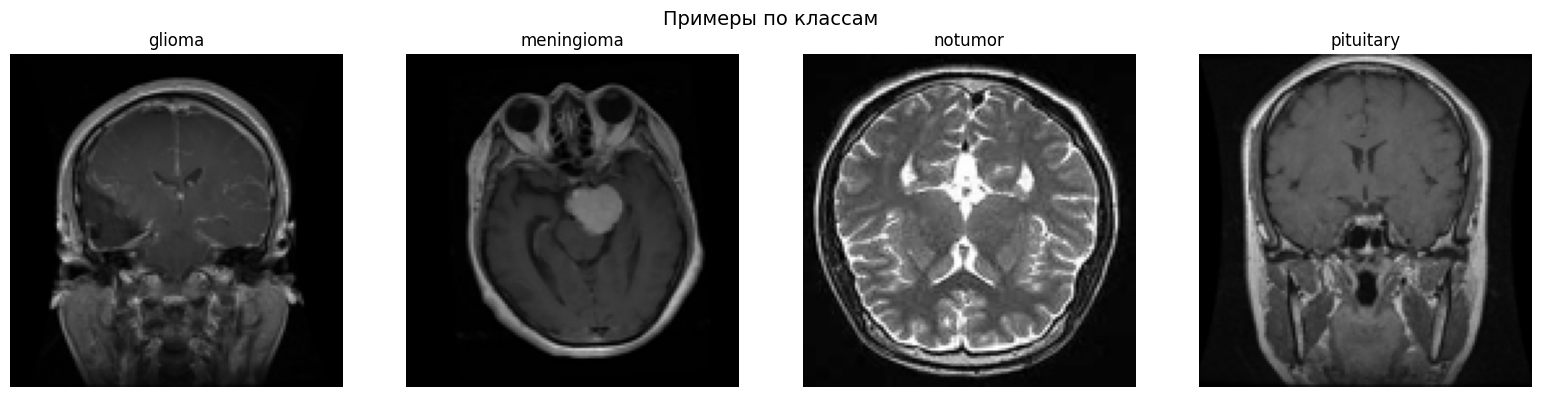

In [ ]:
#По одной картинке на класс
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, cls in zip(axes.ravel(), classes):
    idx = np.where(y_train_all == cls)[0][0]
    ax.imshow(X_train_all[idx])
    ax.set_title(cls)
    ax.axis("off")
plt.suptitle("Примеры по классам", fontsize=14)
plt.tight_layout(); plt.show()

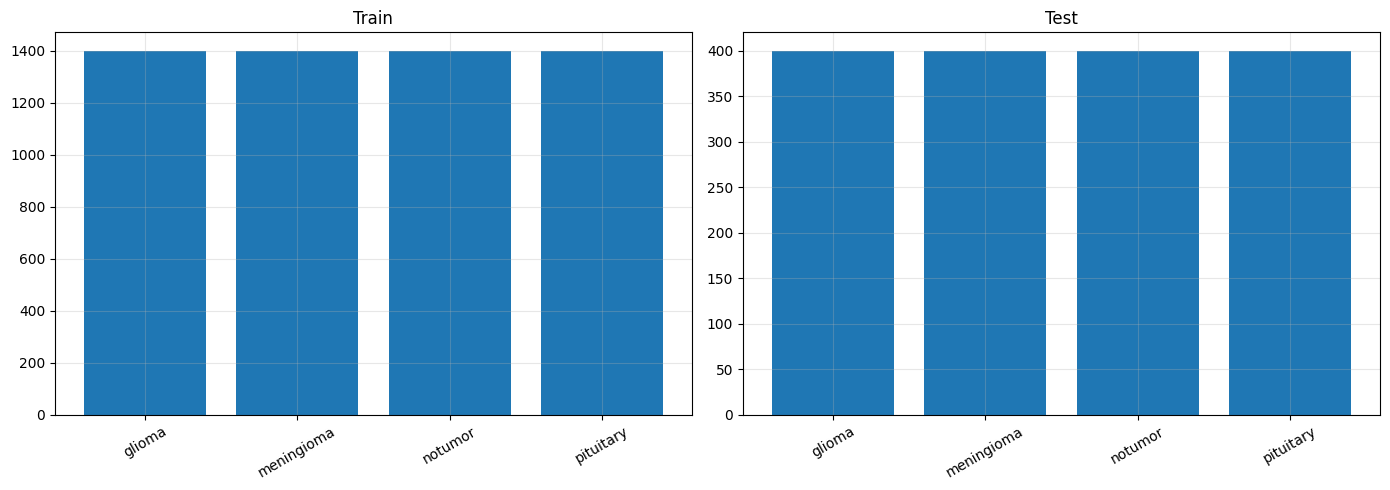

In [ ]:
#Датасет сбалансирован
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (y_, ttl) in zip(axes, [(y_train_all, "Train"), (y_test, "Test")]):
    u, c = np.unique(y_, return_counts=True)
    ax.bar(u, c); ax.set_title(ttl); ax.tick_params(axis='x', rotation=30)
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

##Train /  Val split и Dataset

In [ ]:
le = LabelEncoder()
le.fit(classes)
class_names = list(le.classes_)
print("Классы:", class_names)

y_train_all_enc = le.transform(y_train_all)
y_test_enc      = le.transform(y_test)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_all, y_train_all_enc,
    test_size=0.2, random_state=SEED, stratify=y_train_all_enc
)
print(f"Train: {len(X_train)}, Val: {len(X_val)}, Test: {len(X_test)}")

Классы: [np.str_('glioma'), np.str_('meningioma'), np.str_('notumor'), np.str_('pituitary')]
Train: 4480, Val: 1120, Test: 1600


In [ ]:
#Нормализация по train
X_train_f = X_train.astype(np.float32) / 255.0
mean = X_train_f.mean(axis=(0, 1, 2)).astype(np.float32)
std  = X_train_f.std(axis=(0, 1, 2)).astype(np.float32)
print("mean:", mean, "std:", std)

train_tfms = T.Compose([
    T.ToPILImage(),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(10),
    T.ColorJitter(brightness=0.1, contrast=0.1),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std),
])

eval_tfms = T.Compose([
    T.ToPILImage(),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std),
])

class ImageDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = self.images[idx]
        label = int(self.labels[idx])
        if self.transform:
            img = self.transform(img)
        return img, label

BATCH_SIZE = 64
train_loader = DataLoader(ImageDataset(X_train, y_train, train_tfms),
                          batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(ImageDataset(X_val,   y_val,   eval_tfms),
                          batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(ImageDataset(X_test,  y_test_enc, eval_tfms),
                          batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

mean: [0.14160526 0.14160527 0.14164548] std: [0.17598583 0.17598517 0.17602508]


##Собственная CNN

In [ ]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()
        # Блок 1: 3 -> 32
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1   = nn.BatchNorm2d(32)
        # Блок 2: 32 -> 64
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2   = nn.BatchNorm2d(64)
        # Блок 3: 64 -> 128
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3   = nn.BatchNorm2d(128)
        # Блок 4: 128 -> 128
        self.conv4 = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        self.bn4   = nn.BatchNorm2d(128)

        self.pool    = nn.MaxPool2d(2, 2)
        self.relu    = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(0.5)

        # 128 -> 64 -> 32 -> 16 -> 8 после 4 MaxPool
        self.fc1 = nn.Linear(128 * (IMG_SIZE // 16) * (IMG_SIZE // 16), 256)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(self.relu(self.bn1(self.conv1(x))))
        x = self.pool(self.relu(self.bn2(self.conv2(x))))
        x = self.pool(self.relu(self.bn3(self.conv3(x))))
        x = self.pool(self.relu(self.bn4(self.conv4(x))))
        x = x.view(x.size(0), -1)
        x = self.dropout(self.relu(self.fc1(x)))
        return self.fc2(x)

# Проверка
_model = SimpleCNN(num_classes=len(class_names)).to(device)
with torch.no_grad():
    print(_model(torch.randn(2, 3, IMG_SIZE, IMG_SIZE).to(device)).shape)

torch.Size([2, 4])


##Обучение и оценка

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        out = model(xb)
        loss = criterion(out, yb)
        loss.backward(); optimizer.step()
        running_loss += loss.item() * xb.size(0)
        correct += (out.argmax(1) == yb).sum().item()
        total += xb.size(0)
    return running_loss / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    y_true, y_pred = [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        loss = criterion(out, yb)
        running_loss += loss.item() * xb.size(0)
        pred = out.argmax(1)
        correct += (pred == yb).sum().item()
        total += xb.size(0)
        y_true.extend(yb.cpu().numpy())
        y_pred.extend(pred.cpu().numpy())
    return (running_loss / total, correct / total,
            np.array(y_true), np.array(y_pred))

def fit(model, train_loader, val_loader, epochs=15, lr=1e-3,
        weight_decay=0.0, patience=5, title="Model"):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr, weight_decay=weight_decay
    )
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=2
    )
    history = {"train_loss": [], "val_loss": [],
               "train_acc": [],  "val_acc": [], "time": []}
    best_val_loss, best_state, no_improve = float("inf"), None, 0

    for epoch in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc, _, _ = evaluate(model, val_loader, criterion)
        scheduler.step(va_loss)
        dt = time.time() - t0

        for k, v in zip(["train_loss","val_loss","train_acc","val_acc","time"],
                        [tr_loss, va_loss, tr_acc, va_acc, dt]):
            history[k].append(v)

        print(f"[{title}] Ep {epoch+1:02d}/{epochs} | "
              f"train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.4f} | "
              f"lr {optimizer.param_groups[0]['lr']:.2e} | {dt:.1f}s")

        if va_loss < best_val_loss - 1e-4:
            best_val_loss = va_loss
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f"Early stopping on epoch {epoch+1}")
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    return history

In [18]:
cnn_model = SimpleCNN(num_classes=len(class_names)).to(device)
hist_cnn = fit(cnn_model, train_loader, val_loader,
               epochs=15, lr=1e-3, weight_decay=1e-5,
               patience=4, title="SimpleCNN")

[SimpleCNN] Ep 01/15 | train loss 1.0815 acc 0.5980 | val loss 0.6769 acc 0.7223 | lr 1.00e-03 | 218.5s
[SimpleCNN] Ep 02/15 | train loss 0.6045 acc 0.7484 | val loss 0.4839 acc 0.7911 | lr 1.00e-03 | 202.1s
[SimpleCNN] Ep 03/15 | train loss 0.5087 acc 0.7993 | val loss 0.4267 acc 0.8313 | lr 1.00e-03 | 189.4s
[SimpleCNN] Ep 04/15 | train loss 0.4730 acc 0.8214 | val loss 0.6255 acc 0.7420 | lr 1.00e-03 | 199.2s
[SimpleCNN] Ep 05/15 | train loss 0.4274 acc 0.8386 | val loss 0.3334 acc 0.8759 | lr 1.00e-03 | 190.9s
[SimpleCNN] Ep 06/15 | train loss 0.3699 acc 0.8549 | val loss 0.3235 acc 0.8830 | lr 1.00e-03 | 190.2s
[SimpleCNN] Ep 07/15 | train loss 0.3428 acc 0.8654 | val loss 0.2768 acc 0.8884 | lr 1.00e-03 | 198.6s
[SimpleCNN] Ep 08/15 | train loss 0.3100 acc 0.8783 | val loss 0.5544 acc 0.7670 | lr 1.00e-03 | 191.6s
[SimpleCNN] Ep 09/15 | train loss 0.2751 acc 0.8949 | val loss 0.2353 acc 0.9080 | lr 1.00e-03 | 189.9s
[SimpleCNN] Ep 10/15 | train loss 0.2896 acc 0.8862 | val loss 0

##Transfer Learning: ResNet18

In [19]:
def build_resnet18(num_classes=6, freeze_backbone=False):
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model

resnet_model = build_resnet18(num_classes=len(class_names), freeze_backbone=False).to(device)
hist_resnet = fit(resnet_model, train_loader, val_loader,
                  epochs=10, lr=3e-4, weight_decay=1e-4,
                  patience=3, title="ResNet18")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 130MB/s]


[ResNet18] Ep 01/10 | train loss 0.3042 acc 0.8871 | val loss 0.1748 acc 0.9420 | lr 3.00e-04 | 296.2s
[ResNet18] Ep 02/10 | train loss 0.1294 acc 0.9502 | val loss 0.1210 acc 0.9616 | lr 3.00e-04 | 319.3s
[ResNet18] Ep 03/10 | train loss 0.0859 acc 0.9703 | val loss 0.0691 acc 0.9759 | lr 3.00e-04 | 331.4s
[ResNet18] Ep 04/10 | train loss 0.0703 acc 0.9746 | val loss 0.1320 acc 0.9500 | lr 3.00e-04 | 305.0s
[ResNet18] Ep 05/10 | train loss 0.0510 acc 0.9837 | val loss 0.0717 acc 0.9750 | lr 3.00e-04 | 311.2s
[ResNet18] Ep 06/10 | train loss 0.0298 acc 0.9895 | val loss 0.1001 acc 0.9670 | lr 1.50e-04 | 299.4s
Early stopping on epoch 6


##Кривые обучения

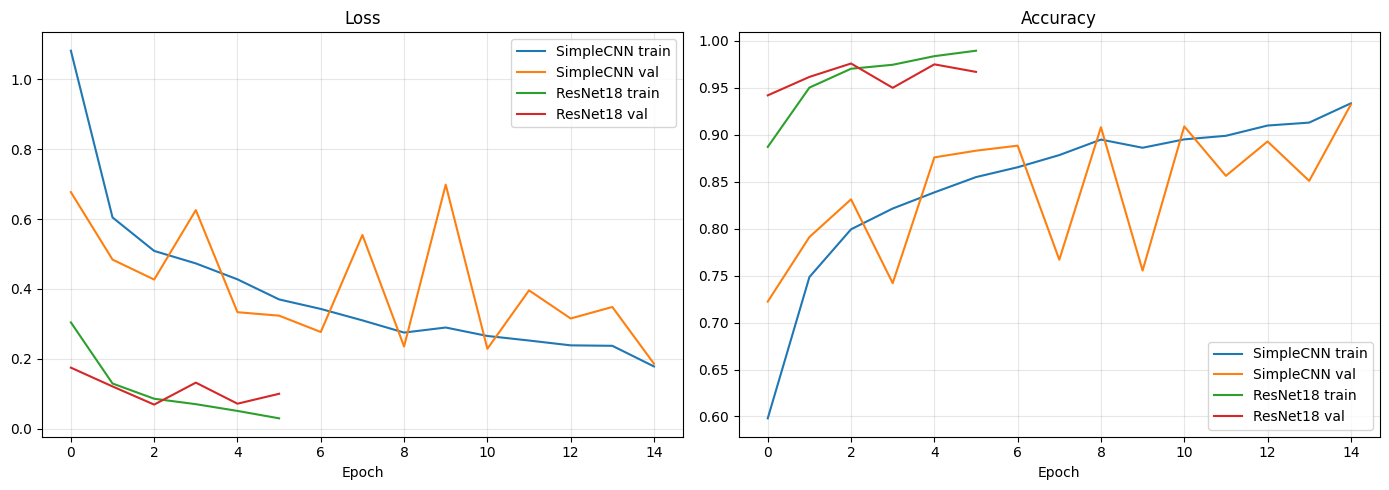

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for hist, name in [(hist_cnn, "SimpleCNN"), (hist_resnet, "ResNet18")]:
    axes[0].plot(hist["train_loss"], label=f"{name} train")
    axes[0].plot(hist["val_loss"],   label=f"{name} val")
    axes[1].plot(hist["train_acc"],  label=f"{name} train")
    axes[1].plot(hist["val_acc"],    label=f"{name} val")

axes[0].set_title("Loss");     axes[0].set_xlabel("Epoch"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

##Оценка на тест и сравнение моделей

In [21]:
criterion = nn.CrossEntropyLoss()

cnn_test_loss, cnn_test_acc, cnn_y_true, cnn_y_pred = evaluate(cnn_model, test_loader, criterion)
print(f"[SimpleCNN] test loss {cnn_test_loss:.4f} | test acc {cnn_test_acc:.4f}")

resnet_test_loss, resnet_test_acc, resnet_y_true, resnet_y_pred = evaluate(resnet_model, test_loader, criterion)
print(f"[ResNet18]  test loss {resnet_test_loss:.4f} | test acc {resnet_test_acc:.4f}")

[SimpleCNN] test loss 0.7633 | test acc 0.8531
[ResNet18]  test loss 0.3609 | test acc 0.9294


In [23]:
print("SimpleCNN: classification report")
print(classification_report(cnn_y_true, cnn_y_pred, target_names=class_names, digits=4))

print("ResNet18: classification report")
print(classification_report(resnet_y_true, resnet_y_pred, target_names=class_names, digits=4))

SimpleCNN: classification report
              precision    recall  f1-score   support

      glioma     0.9960    0.6225    0.7662       400
  meningioma     0.7716    0.8025    0.7868       400
     notumor     0.7663    1.0000    0.8677       400
   pituitary     0.9587    0.9875    0.9729       400

    accuracy                         0.8531      1600
   macro avg     0.8732    0.8531    0.8484      1600
weighted avg     0.8732    0.8531    0.8484      1600

ResNet18: classification report
              precision    recall  f1-score   support

      glioma     0.9719    0.7775    0.8639       400
  meningioma     0.8305    0.9800    0.8991       400
     notumor     0.9569    1.0000    0.9780       400
   pituitary     0.9846    0.9600    0.9722       400

    accuracy                         0.9294      1600
   macro avg     0.9360    0.9294    0.9283      1600
weighted avg     0.9360    0.9294    0.9283      1600



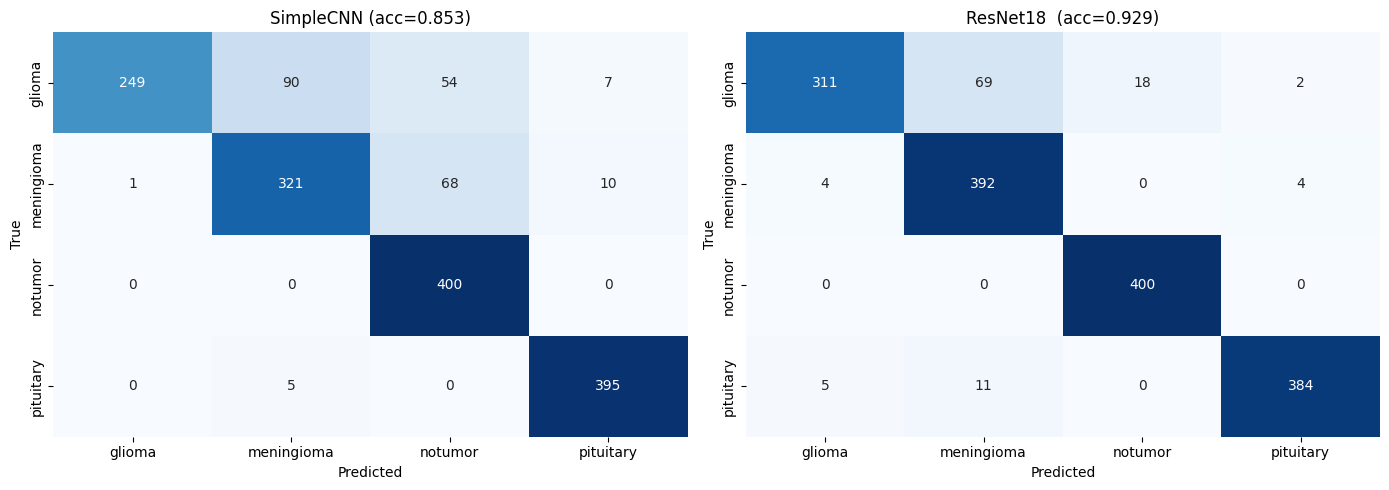

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (y_t, y_p, ttl) in zip(axes, [
    (cnn_y_true,    cnn_y_pred,    f"SimpleCNN (acc={cnn_test_acc:.3f})"),
    (resnet_y_true, resnet_y_pred, f"ResNet18  (acc={resnet_test_acc:.3f})"),
]):
    cm = confusion_matrix(y_t, y_p)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names,
                ax=ax, cbar=False)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(ttl)
plt.tight_layout(); plt.show()

In [25]:
summary = pd.DataFrame({
    "Модель":         ["SimpleCNN", "ResNet18"],
    "Test accuracy":  [cnn_test_acc, resnet_test_acc],
    "Test loss":      [cnn_test_loss, resnet_test_loss],
    "Эпох обучения":  [len(hist_cnn["train_loss"]), len(hist_resnet["train_loss"])],
    "Время (сек)":    [sum(hist_cnn["time"]), sum(hist_resnet["time"])],
    "Параметров (M)": [
        sum(p.numel() for p in cnn_model.parameters()) / 1e6,
        sum(p.numel() for p in resnet_model.parameters()) / 1e6,
    ],
})
summary

,Модель,Test accuracy,Test loss,Эпох обучения,Время (сек),Параметров (M)
0,SimpleCNN,0.853125,0.763253,15,2918.864603,2.339972
1,ResNet18,0.929375,0.360934,6,1862.444252,11.178564
